# 원본 PCB 한 장 정상/불량 — 처음부터 새로 학습

**주 실험은 원본 전용 CNN의 무작위 초기화 학습입니다.** 기존 패치 모델/사전학습 checkpoint를 로드하지 않습니다. 이전 전이학습 노트북은 비교 기록으로 보존합니다.

- 입력: 원본 640×640 사진 한 장. 정상 기준 사진과 bbox는 추론 입력에 필요하지 않습니다.
- 라벨: 정상 기준 원본 0 / 불량 검사 원본 1. 원본 사진을 별도 표본으로 학습합니다.
- 원본 Crop/resize 없음. 같은 원본 쌍은 같은 split; `group00041` 검증 고정; 공식 test 미사용.
- 초기 분류-only pilot 기록을 보존하고, 주 모델은 결함 위치의 보조 정답도 활용해 작은 결함 특징을 학습합니다.
- 보조 정답은 학습용 target입니다. 모델 입력은 한 장뿐이며 정상 기준 사진/정답 마스크가 추론에 들어가지 않습니다.
- 모든 학습 가중치를 새로 생성해 전체 CNN을 학습하고 고정 임계값 0.5의 validation Macro F1로 선택합니다.

In [1]:
# WSL에서 가상환경에 설치된 CUDA 라이브러리를 먼저 연결합니다.
from pathlib import Path
import sys, sysconfig, ctypes
if sys.platform == 'linux':
    nvidia = Path(sysconfig.get_paths()['purelib']) / 'nvidia'
    for name in ['libcudart.so.12', 'libcublasLt.so.12', 'libcublas.so.12', 'libcufft.so.11', 'libcurand.so.10', 'libnvJitLink.so.12', 'libcusparse.so.12', 'libcusolver.so.11', 'libcudnn.so.9']:
        for lib in nvidia.glob('*/lib/' + name):
            ctypes.CDLL(str(lib), mode=ctypes.RTLD_GLOBAL)
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display, Image as DisplayImage, Markdown
from src.runtime import configure_runtime
from src.full_image_data import prepare_full_image_data

ROOT = Path.cwd()
print('TensorFlow:', tf.__version__)
print(configure_runtime())
original_summary = prepare_full_image_data(ROOT)
original_frame = pd.read_csv(ROOT / 'data/split/full_image_v1/images.csv')
display(pd.crosstab(original_frame.split, original_frame.label))

I0000 00:00:1795049869.310745    2659 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795049869.347302    2659 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795049881.148945    2659 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
{'optimizer_options': {'disable_model_pruning': False, 'disable_meta_optimizer': False}, 'gpu_devices': ["PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')"]}


W0000 00:00:1795049887.521589    2659 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


{
  "counts": [
    {
      "split": "train",
      "label": "defect",
      "images": 800
    },
    {
      "split": "train",
      "label": "normal",
      "images": 800
    },
    {
      "split": "val",
      "label": "defect",
      "images": 200
    },
    {
      "split": "val",
      "label": "normal",
      "images": 200
    }
  ],
  "rows": 2000,
  "duplicate_pixel_rows_within_train": 2,
  "train_sources": 800,
  "validation_sources": 200,
  "cross_split_pixel_overlap": 0,
  "cross_split_group_overlap": 0,
  "test_images_read": 0,
  "native_resolution": [
    640,
    640
  ],
  "cropped": false,
  "manifest_sha256": "4ce69ca689f9825e86d545edb56415f0b34f3716564579376d257c124ceaa753"
}


label,defect,normal
split,,
train,800,800
val,200,200


## 초기 분류-only pilot 기록

원본 사진의 정상/불량 라벨만으로 학습한 pilot은 완료되지 않았습니다. 초기 기록 5 epoch에서 검증 Accuracy 0.95를 얻었지만, 학습 비용과 작은 결함의 감독 정보를 고려해 보조 정답을 쓰는 새 모델로 전환했습니다. 이 pilot의 미완료 결과를 최종 성능으로 비교하지 않습니다.

In [2]:
# 초기 pilot은 자동으로 다시 학습하지 않고 기록만 확인합니다.
pilot_history = ROOT / 'results/full_scratch/full_scratch_001/history.csv'
if pilot_history.exists():
    display(pd.read_csv(pilot_history).tail())
    print('미완료 pilot: 최종 성능 비교에서 제외. 아래 새 모델을 사용합니다.')

,epoch,accuracy,learning_rate,loss,val_accuracy,val_defect_recall,val_loss,val_macro_f1,val_normal_fpr,val_numpy_accuracy
0,0,0.507500,0.0003,0.746337,0.5000,0.000,0.700889,0.333333,0.00,0.5000
1,1,0.483125,0.0003,0.706687,0.4975,0.105,0.697453,0.405989,0.11,0.4975
2,2,0.495625,0.0003,0.700922,0.5000,1.000,0.696650,0.333333,1.00,0.5000
3,3,0.524375,0.0003,0.690061,0.6100,0.990,0.594363,0.544180,0.77,0.6100
4,4,0.855000,0.0003,0.357357,0.9500,0.960,0.151609,0.949995,0.06,0.9500


미완료 pilot: 최종 성능 비교에서 제외. 아래 새 모델을 사용합니다.


## 결함 위치 보조 정답 — 학습 때만 사용

정렬된 정상 기준/검사 원본의 128 이상 밝기 차이 중 주석 bbox 내부를 정답으로 만듭니다. 작은 1픽셀 결함도 남도록 max pooling해 160×160 정답 맵을 저장합니다. 입력 원본은 계속 640×640이며 자르지 않습니다.

새 CNN은 원본 한 장으로 정상/불량과 보조 영역을 함께 학습합니다. 보조 영역 학습이 희소한 결함 특징에 신호를 줍니다. 배포 모델에는 정상/불량 출력만 남기며, 기준 사진/정답 맵은 입력에 포함되지 않습니다.

In [2]:
# 기존 모델 가중치를 사용하지 않고 원본/주석으로 학습용 보조 target만 생성합니다.
from src.full_supervised import prepare_supervision
auxiliary_summary = prepare_supervision(ROOT)
display(auxiliary_summary)

ValueError: 보조 감독 설정이 변경됐습니다. 새 버전이 필요합니다.

## 새 CNN 학습 — 완료

11 epoch 체크포인트에서 재개하여 17 epoch까지 학습했습니다. 최고 모델은 12 epoch이며 validation 정확도는 98.75%, Macro F1은 약 0.9875입니다. CPU 재검증과 최종 보고서를 완료했습니다.

WSL2 RTX 5060에서 TensorFlow 2.21.0 및 Keras 3.15.1을 사용했습니다. 학습은 batch 4, 최대 20 epoch, patience 5, seed 42이며 validation Macro F1을 기준으로 모델을 선택합니다.

In [2]:
# 완료된 학습을 다시 실행하지 않도록 기본값을 끕니다.
START_TRAINING = False
RESUME_TRAINING = True
if START_TRAINING:
    from src.full_supervised import train_supervised_scratch
    supervised_result = train_supervised_scratch(ROOT, resume=RESUME_TRAINING)
    display(supervised_result)
else:
    supervised_result = None
    print('학습 실행을 건너뜁니다. 기존 완료 결과는 results/full_scratch에서 확인하세요.')

저장된 11 epoch 가중치/Adam 상태 복원 → 12 epoch부터 재개


W0000 00:00:1795049919.787507    2788 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1795049919.787551    2783 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1795049919.787507    2781 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1795049919.787924    2782 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1795049919.787947    2785 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1795049919.787924    2784 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1795049919.788034    2787 gpu_kernel_to_blob_pass.cc:190] Failed to co

원본 보조 감독 CNN: 1600장, 저장된 자체 모델 재개, 입력 사진 1장


/mnt/c/Users/KDT62/PycharmProjects/DNN_project/DNN_project/.venv-wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795049926.494346    2746 cuda_dnn.cc:461] Loaded cuDNN version 90300
W0000 00:00:1795049926.689052    2840 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1795049926.689129    2838 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1795049926.689133    2848 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1795049926.689046    2841 gpu_kernel_to_blob_pass.cc:190] Fail

epoch=12 train_acc=0.9837 val_acc=0.9875 macro_f1=0.9875 recall=0.9950 normal_fpr=0.0200 elapsed=104s
epoch=13 train_acc=0.9875 val_acc=0.9750 macro_f1=0.9750 recall=0.9950 normal_fpr=0.0450 elapsed=141s
epoch=14 train_acc=0.9844 val_acc=0.9425 macro_f1=0.9423 recall=1.0000 normal_fpr=0.1150 elapsed=177s
epoch=15 train_acc=0.9912 val_acc=0.9825 macro_f1=0.9825 recall=1.0000 normal_fpr=0.0350 elapsed=213s
epoch=16 train_acc=0.9919 val_acc=0.9725 macro_f1=0.9725 recall=1.0000 normal_fpr=0.0550 elapsed=249s
epoch=17 train_acc=0.9937 val_acc=0.9775 macro_f1=0.9775 recall=1.0000 normal_fpr=0.0450 elapsed=286s
{
  "run_name": "full_scratch_aux_001",
  "metrics": {
    "samples": 400,
    "accuracy": 0.9875,
    "balanced_accuracy": 0.9875,
    "defect_precision": 0.9802955665024631,
    "defect_recall": 0.995,
    "defect_f1": 0.9875930521091811,
    "macro_f1": 0.987499296835447,
    "normal_false_positive_rate": 0.02,
    "defect_false_negative_rate": 0.005,
    "roc_auc": 0.998875,
    "a

{'run_name': 'full_scratch_aux_001',
 'metrics': {'samples': 400,
  'accuracy': 0.9875,
  'balanced_accuracy': 0.9875,
  'defect_precision': 0.9802955665024631,
  'defect_recall': 0.995,
  'defect_f1': 0.9875930521091811,
  'macro_f1': 0.987499296835447,
  'normal_false_positive_rate': 0.02,
  'defect_false_negative_rate': 0.005,
  'roc_auc': 0.998875,
  'average_precision': 0.9988736581051642,
  'true_normal': 196,
  'false_defect': 4,
  'missed_defect': 1,
  'true_defect': 199,
  'threshold': 0.5,
  'split': 'validation',
  'unit': 'full_640_image',
  'official_test_evaluated': False},
 'initialization': 'random',
 'patch_weights_used': False,
 'input_images': 1,
 'epochs_completed': 17,
 'best_epoch': 12,
 'elapsed_seconds': 291.4112682299999,
 'parameters': 284026,
 'resumed_from_epoch': 11,
 'elapsed_seconds_scope': 'this_session',
 'model_path': '/mnt/c/Users/KDT62/PycharmProjects/DNN_project/DNN_project/models/full_scratch_aux_001/best.keras',
 'status': 'completed'}

## 원본 한 장 추론과 CPU 검증

저장된 주 모델의 입력은 원본 한 장, 출력은 정상/불량 한 개입니다. 기준 사진이나 정답 맵을 제공하지 않고 validation 원본 전체를 CPU에서도 다시 추론합니다. 이전 전이학습 결과는 참고 기록으로만 비교합니다.

In [3]:
if (ROOT / 'results/full_scratch/full_scratch_aux_001/run_result.json').exists():
    # 배포 모델은 정답 맵이나 정상 기준 사진 없이 원본 한 장만 받습니다.
    from tensorflow import keras
    from PIL import Image as PILImage
    from src.full_image_data import full_image_dataset
    from src.binary_evaluate import binary_scores, collect_binary_predictions
    from src.full_image_predict import predict_full_image

    PRIMARY_RUN = 'full_scratch_aux_001'
    PRIMARY_OUTPUT = ROOT / 'results/full_scratch' / PRIMARY_RUN
    PRIMARY_MODEL = ROOT / 'models' / PRIMARY_RUN / 'best.keras'
    validation_data, validation_frame = full_image_dataset(ROOT, 'val', batch_size=4)
    stored = pd.read_csv(PRIMARY_OUTPUT / 'validation_predictions.csv')
    with tf.device('/CPU:0'):
        cpu_model = keras.models.load_model(PRIMARY_MODEL, compile=False)
        assert len(cpu_model.inputs) == 1 and cpu_model.output_shape == (None, 1)
        cpu_labels, cpu_scores = collect_binary_predictions(cpu_model, validation_data)
        cpu_device = cpu_model(next(iter(validation_data))[0], training=False).device
    assert np.array_equal(cpu_labels, stored.target.values)
    max_cpu_gpu_delta = float(abs(cpu_scores-stored.sigmoid_score.values).max())
    label_agreement = float(((cpu_scores > .5).astype(int) == stored.predicted_target.values).mean())
    assert max_cpu_gpu_delta < 1e-4 and label_agreement == 1.0
    examples, deltas = [], []
    for target in [0, 1]:
        row = stored[stored.target == target].iloc[0]
        with PILImage.open(ROOT / row.image_path) as image:
            prediction = predict_full_image(PRIMARY_MODEL, image)
        examples.append(dict(true_label=row.label, image_path=row.image_path, **prediction))
        deltas.append(abs(prediction['sigmoid_score']-float(row.sigmoid_score)))
    assert max(deltas) < 1e-4
    verification = dict(samples=len(cpu_labels), model=PRIMARY_RUN, cpu_device=cpu_device,
        max_cpu_gpu_delta=max_cpu_gpu_delta, label_agreement=label_agreement,
        max_inference_delta=float(max(deltas)), input_images=1, ground_truth_mask_input=False,
        cpu_metrics=binary_scores(cpu_labels, cpu_scores), verified=True)
    (ROOT / 'results/full_scratch/inference_verification.json').write_text(json.dumps(verification, indent=2))
    display(verification)
    display(pd.DataFrame(examples))
else:
    print('학습 일시 중지 상태입니다. TRAINING_HANDOFF.md에 따라 재개·완료한 뒤 실행하세요.')

/mnt/c/Users/KDT62/PycharmProjects/DNN_project/DNN_project/.venv-wsl/lib/python3.11/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['single_original_image']
Received: inputs=Tensor(shape=(1, 640, 640, 1))
  warnings.warn(msg)


{'samples': 400,
 'model': 'full_scratch_aux_001',
 'cpu_device': '/job:localhost/replica:0/task:0/device:CPU:0',
 'max_cpu_gpu_delta': 1.1046808624515236e-06,
 'label_agreement': 1.0,
 'max_inference_delta': 1.9209289603416835e-08,
 'input_images': 1,
 'ground_truth_mask_input': False,
 'cpu_metrics': {'samples': 400,
  'accuracy': 0.9875,
  'balanced_accuracy': 0.9875,
  'defect_precision': 0.9802955665024631,
  'defect_recall': 0.995,
  'defect_f1': 0.9875930521091811,
  'macro_f1': 0.987499296835447,
  'normal_false_positive_rate': 0.02,
  'defect_false_negative_rate': 0.005,
  'roc_auc': 0.998875,
  'average_precision': 0.9988736581051642,
  'true_normal': 196,
  'false_defect': 4,
  'missed_defect': 1,
  'true_defect': 199,
  'threshold': 0.5},
 'verified': True}

,true_label,image_path,target,label,korean,sigmoid_score,threshold,input_images,interpretation
0,normal,data/group00041/00041/00041000_temp.jpg,0,normal,정상,0.000159,0.5,1,보정되지 않은 모델 점수이며 실제 불량 확률이나 모델 정확도가 아닙니다.
1,defect,data/group00041/00041/00041000_test.jpg,1,defect,불량,1.000000,0.5,1,보정되지 않은 모델 점수이며 실제 불량 확률이나 모델 정확도가 아닙니다.


,run_name,initialization,accuracy,macro_f1,defect_recall,normal_false_positive_rate
0,full_frozen_001,patch_transfer_reference,0.9525,0.952433,0.990,0.085
1,full_finetuned_001,patch_transfer_reference,0.9550,0.954928,0.995,0.085
2,full_scratch_aux_001,random_from_scratch_primary,0.9875,0.987499,0.995,0.020


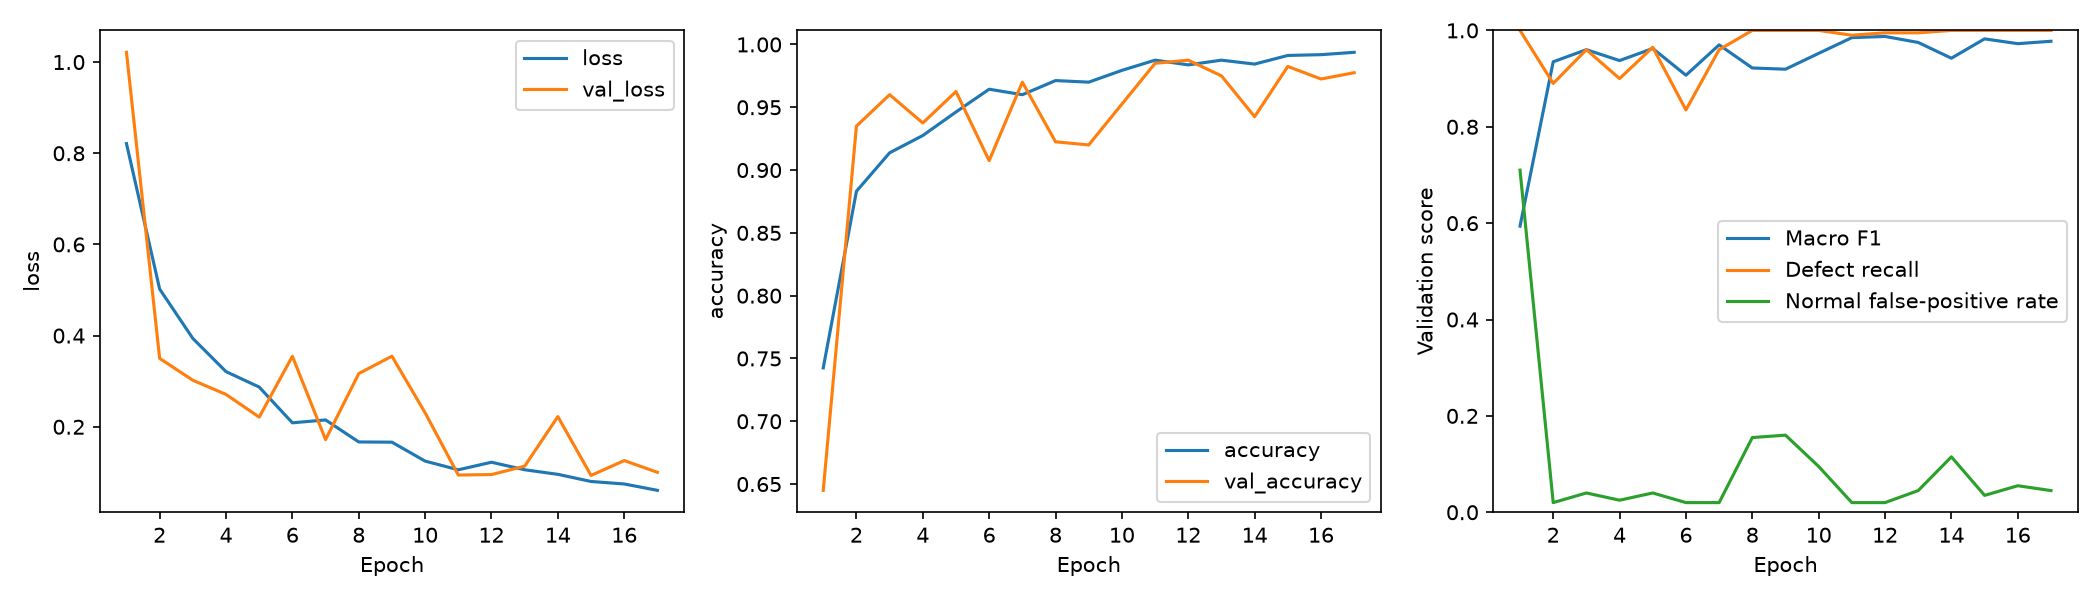

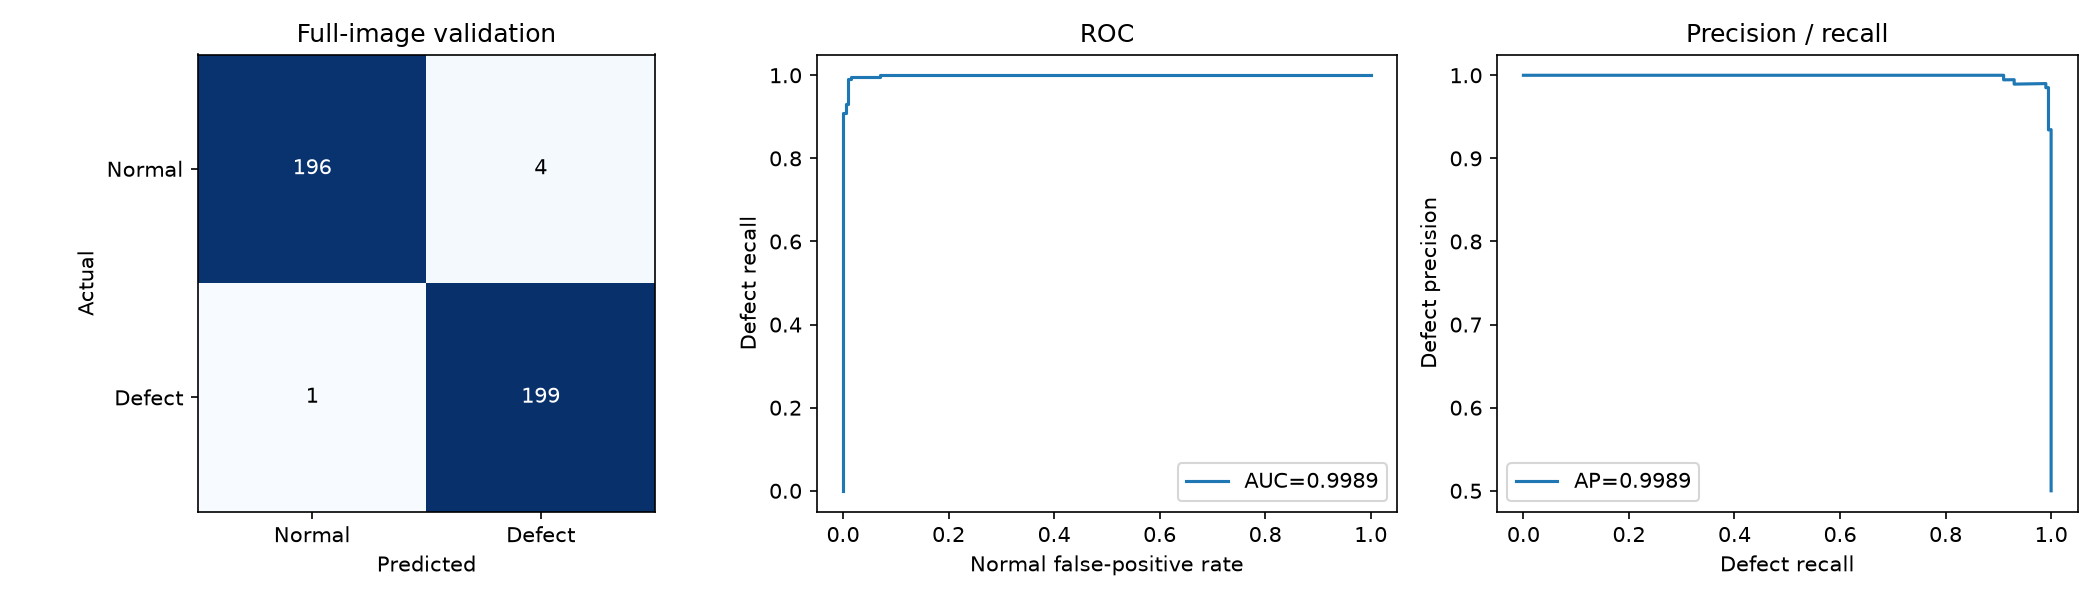

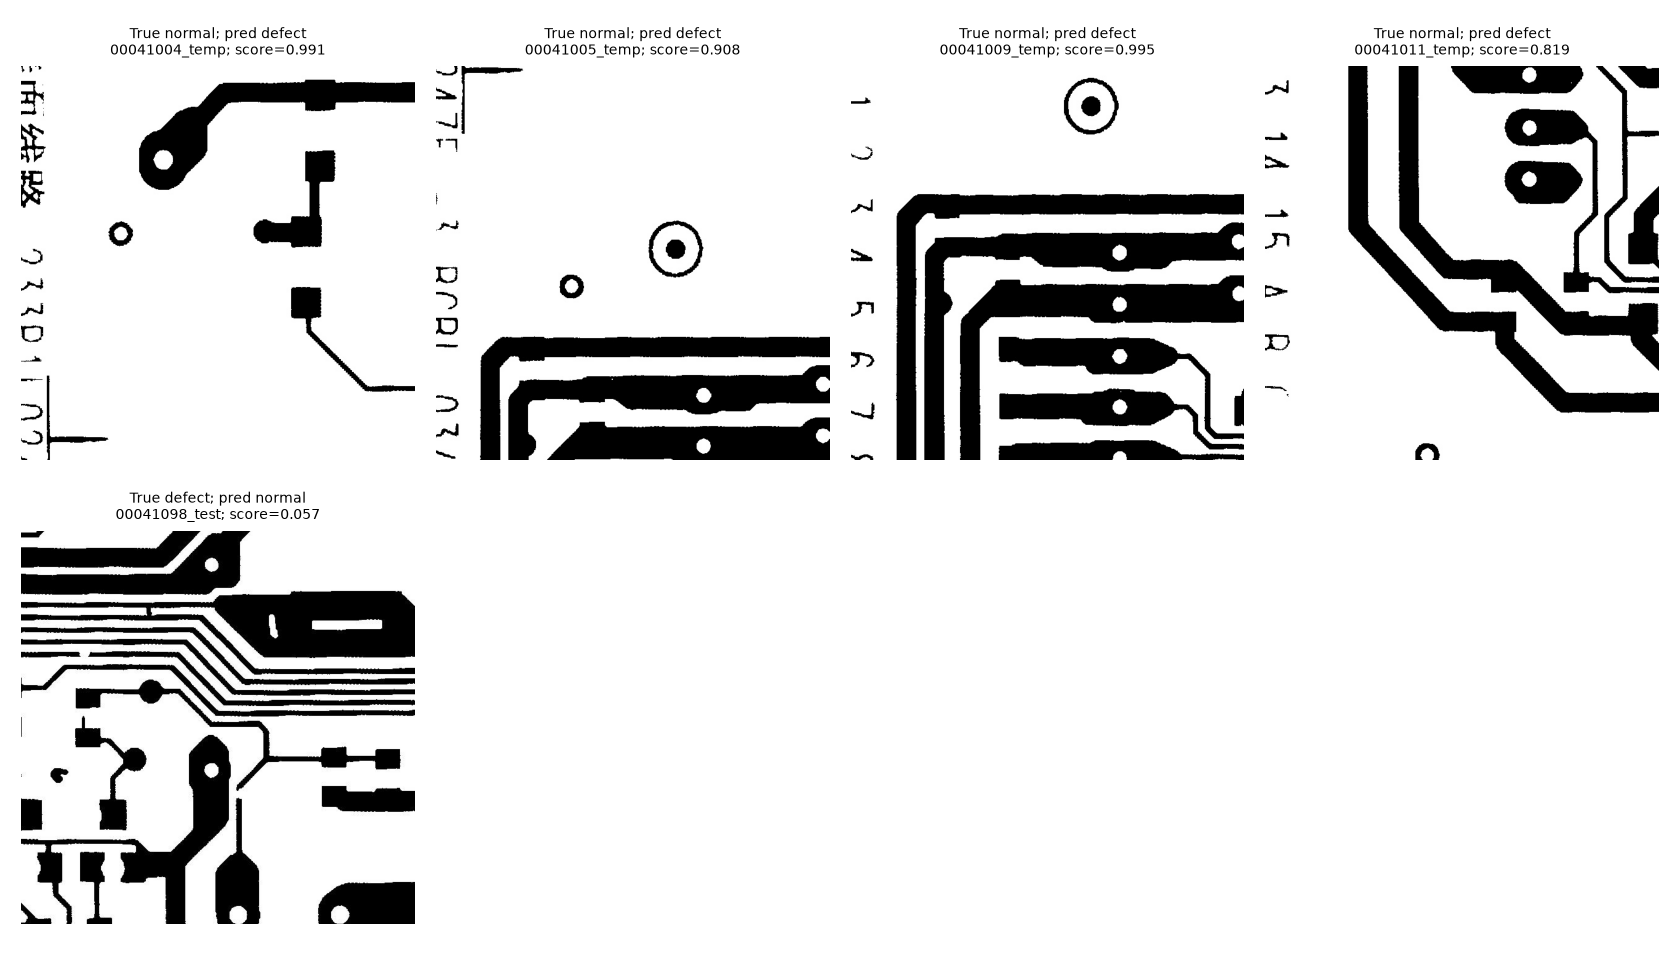

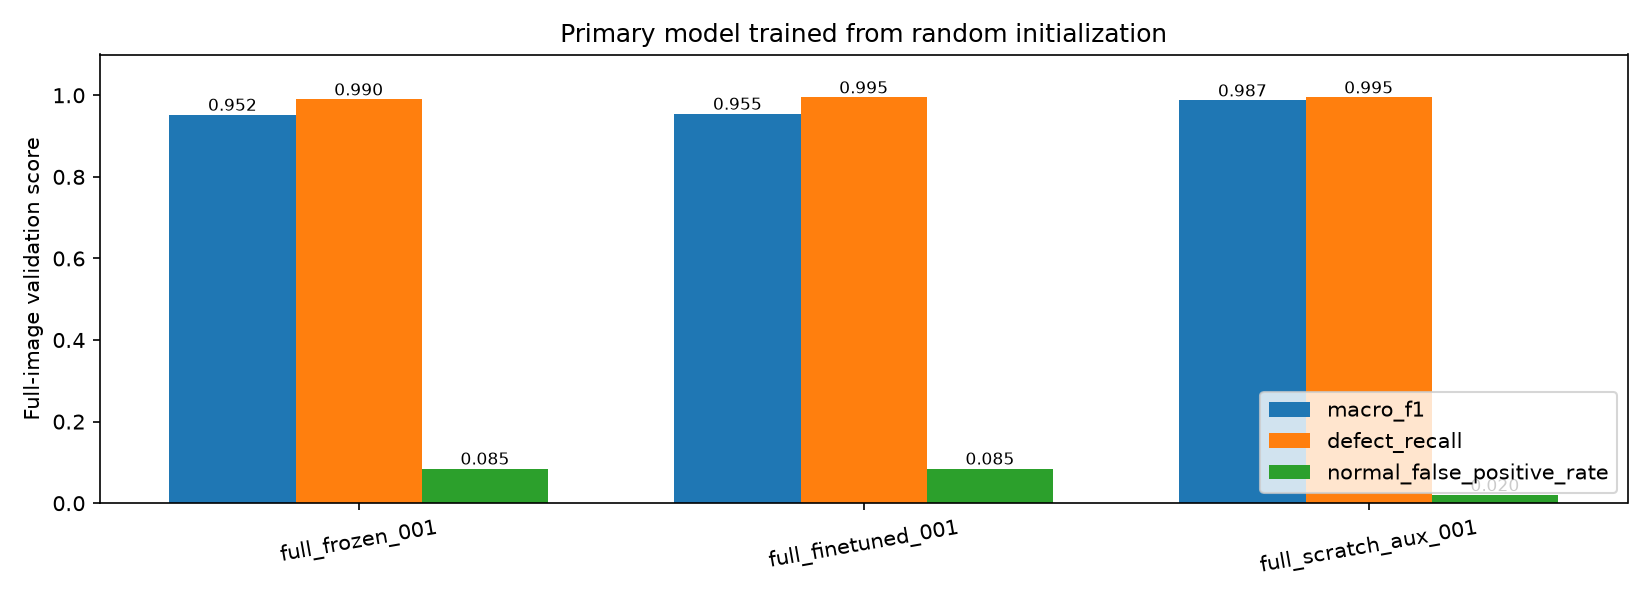

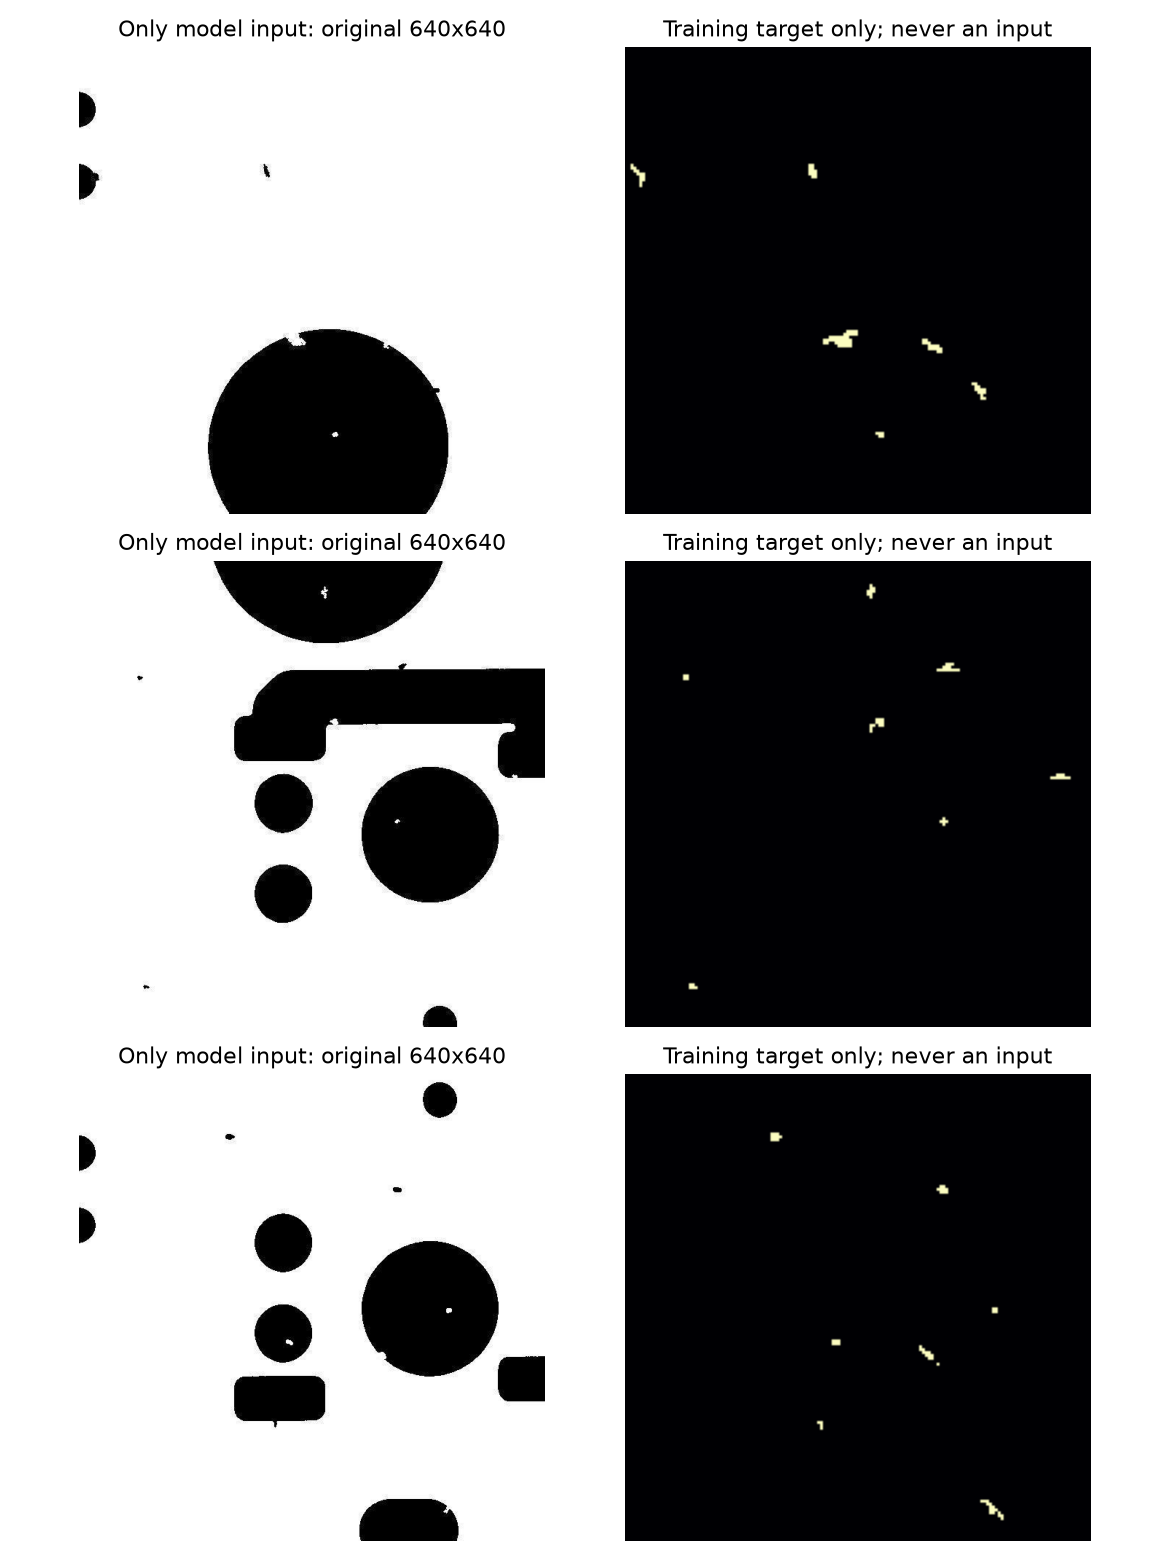

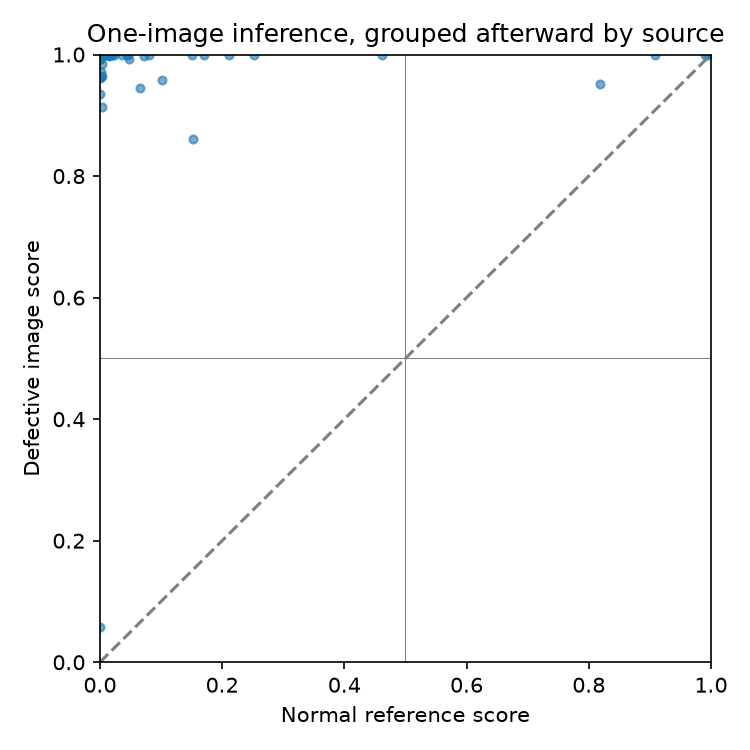

# 원본 한 장 분류 — 처음부터 학습한 주 실험

## 확정된 요구사항

새 파일 `full_image_from_scratch.ipynb`에서 진행했다. 입력은 **원본 640×640 사진 한 장**이며
정상 기준 사진, bbox, 정답 마스크를 입력받지 않는다. 기존 패치 모델과 사전학습 가중치는 사용하지 않았다.
기존 `full_image_classification.ipynb`는 전이학습 비교 기록으로 보존했다.

학습 원본은 정상 800장/불량 800장, 검증 원본은 정상 200장/불량 200장이다.
같은 PCB 쌍을 한 split에 넣고 `group00041`을 고정 검증 그룹으로 유지했다.
원본을 Crop하거나 resize하지 않았다. 모든 입력 픽셀은 저장 모델에서 1/255 정규화한다.
공식 test는 학습·선택에 사용하지 않았다.

## 현재 방식

CNN의 모든 가중치를 새로 생성했다. 가벼운 encoder/decoder와 학습된 attention을 사용한다.
정상/불량 이미지 라벨뿐 아니라, 기존 위치 주석과 정렬된 원본 쌍의 차이를 학습 보조 정답으로 사용했다.
정상 기준과 검사 원본의 밝기 차이가 128 이상이고 bbox 내부인 픽셀을 결함 정답으로 만들고,
작은 변화도 남게 max pooling해 160×160 정답 맵을 저장했다. 이 맵은 **입력이 아닌 학습 target**이다.
정상 원본의 정답 맵은 0이다. 보조 loss의 픽셀 가중치는 train 양성 픽셀 비율로만 계산했다.

학습 입력 텐서는 하나이며 shape은 `(batch,640,640,1)`이다. 위치 감독은 추가 loss를 통해
결함 특징을 배우도록 돕는다. 배포 `.keras`에서는 정상/불량 출력 하나만 제공한다.
같은 입력으로 예측한 영역을 attention에 사용하며 정답 영역을 attention 입력으로 주입하지 않는다.

Adam 0.0003, clipnorm 1.0, batch 4, 최대 20 epoch, EarlyStopping patience 5, seed 42다.
학습할 때만 원본/정답 맵에 같은 회전·반전을 적용한다. 임계값은 0.5로 고정했다.
최고 모델은 이미지 단위 validation Macro F1로 저장 후 재로드했다.
초기 분류-only GroupNorm pilot은 5 epoch 후 중단했고 최종 비교에서 제외했다.
이 미완료 pilot은 초기 검증 Accuracy 0.95에 도달했으나 수렴 상한을 평가한 실험은 아니다.

## 실측 비교

| 모델 | 초기화 | Accuracy | Macro F1 | 불량 Recall | 정상 오탐률 |
|---|---|---:|---:|---:|---:|
| full_frozen_001 | patch_transfer_reference | 0.9525 | 0.9524 | 0.9900 | 8.50% |
| full_finetuned_001 | patch_transfer_reference | 0.9550 | 0.9549 | 0.9950 | 8.50% |
| full_scratch_aux_001 | random_from_scratch_primary | 0.9875 | 0.9875 | 0.9950 | 2.00% |

현재 주 실험 `full_scratch_aux_001`은 검증 원본 400장 중 정상 오탐 4장,
불량 미검출 1장이었다. 실제 17 epoch를 실행했고
최고 checkpoint는 12 epoch다.

원본 validation 400장 전체의 CPU/Metal 판정 일치율은 100.00%, 최대 점수 차이는 1.1e-06였다. 독립 한 장 추론의 최대 점수 차이는 1.92e-08였다.

같은 PCB 쌍을 추론 후 묶어 점수를 분석하면 200쌍 중
195쌍에서 정상/불량 양쪽 판정이 모두 맞았다.
200쌍에서 불량 점수가 정상 점수보다 높았다.
이 분석은 쌍을 입력받는 모델이라는 의미가 아니며 출처 혼입 가능성을 배제하는 증거도 아니다.
쌍별 점수와 판정은 `paired_validation.csv`, 산점도는 `paired_scores.png`에 저장했다.

## 해석과 후속 검증

- 수치는 고정 그룹 validation 결과이며 독립 최종 test 성능이 아니다.
- 이전 패치 모델의 4,415개 패치 지표와 원본 400장 지표는 직접 비교하지 않는다.
- 이번 주 실험의 가중치는 무작위 초기화이며, 과거 전이 모델은 참고 결과로만 표시했다.
- 정상 원본이 기준 사진, 불량 원본이 검사 사진이라는 출처 혼입 가능성은 남아 있다.
  보조 위치 감독을 썼다는 사실만으로 실제 결함만 배웠다고 단정하지 않는다.
- DeepPCB의 합성 불량과 제한된 기판 패턴, 공식 trainval/test의 그룹 공유 제한이 있다.
- 단일 사진의 정상/불량만 검증했다. 배포 출력의 sigmoid는 실제 불량 확률이나 정확도가 아니다.
- 160×160 보조 정답은 학습 감독에 사용했으며, 위치 탐지 성능을 최종 지표로 검증한 것은 아니다.

## 한 장 추론

```python
from PIL import Image
from src.full_image_predict import predict_full_image
with Image.open("path/to/pcb_640.png") as image:
    result = predict_full_image("models/full_scratch_aux_001/best.keras", image)
print(result["korean"], result["sigmoid_score"])
```

결과 경로는 `results/full_scratch/selected_model.json`에 기록했다.
학습 로그, 원본 예측 CSV, 분류 보고서, 혼동행렬/ROC/PR, 오분류는 `results/full_scratch/full_scratch_aux_001/`에 있다.
모델은 `models/full_scratch_aux_001/best.keras`와 `metadata.json`이다.
학습용 정답 맵은 `data/processed/full_scratch_aux_v1/`, 목록은 `data/split/full_scratch_aux_v1/`에 있다.
원본 파일과 이전 노트북/모델은 변경하지 않았다.


In [4]:
if (ROOT / 'results/full_scratch/full_scratch_aux_001/run_result.json').exists():
    # 이전 미완료 pilot은 비교에서 제외하고, 무작위 초기화 주 모델을 명확히 표시합니다.
    from src.full_scratch_report import write_scratch_report
    comparison = write_scratch_report(ROOT)
    display(comparison[['run_name', 'initialization', 'accuracy', 'macro_f1', 'defect_recall', 'normal_false_positive_rate']])
    for filename in ['learning_curves.png', 'evaluation.png', 'misclassified.png']:
        display(DisplayImage(filename=str(PRIMARY_OUTPUT / filename), width=1000))
    for filename in ['model_comparison.png', 'training_target_examples.png', 'paired_scores.png']:
        display(DisplayImage(filename=str(ROOT / 'results/full_scratch' / filename), width=1000))
    display(Markdown((ROOT / 'results/full_scratch/from_scratch_report.md').read_text(encoding='utf-8')))
else:
    print('학습 일시 중지 상태입니다. TRAINING_HANDOFF.md에 따라 재개·완료한 뒤 실행하세요.')

## 내 원본 사진 한 장 판정

아래 `IMAGE_PATH`에 640×640 PNG/JPG 원본 경로를 넣고 실행하세요. 모델은 이미지를 자동으로 자르거나 축소하지 않습니다.

In [ ]:
if (ROOT / 'results/full_scratch/full_scratch_aux_001/run_result.json').exists():
    # 예: IMAGE_PATH = ROOT / 'my_pcb_640.png'
    IMAGE_PATH = None
    if IMAGE_PATH is not None:
        with PILImage.open(Path(IMAGE_PATH).expanduser()) as image:
            own_result = predict_full_image(PRIMARY_MODEL, image)
        display(DisplayImage(filename=str(IMAGE_PATH), width=500))
        print('판정:', own_result['korean'])
        print('모델 점수:', own_result['sigmoid_score'])
        print(own_result['interpretation'])
    else:
        print('IMAGE_PATH에 원본 한 장의 경로를 입력하세요.')
else:
    print('학습 일시 중지 상태입니다. TRAINING_HANDOFF.md에 따라 재개·완료한 뒤 실행하세요.')